<a href="https://colab.research.google.com/github/Natt-8510/Inteligencia-Artificial/blob/main/1_Clasificaci%C3%B3n_de_la_flor_iris_como_una_red_Multicapa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

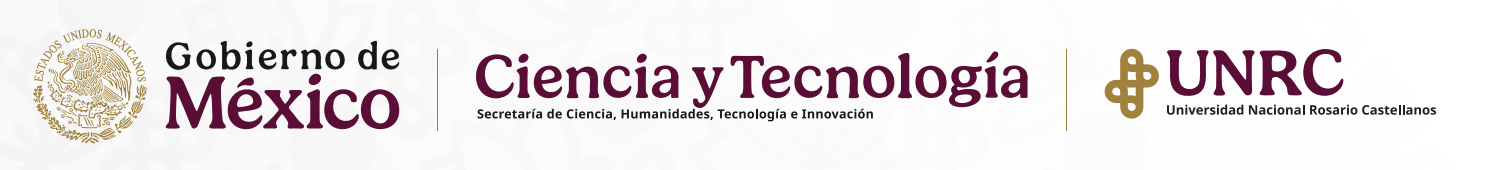

**Octubre-20**

# Introducción

Utilizarremos herramientas como "tensorflow", "numpy" y "padas" para poder clasificar un ejemplo de una flor, que en este caso utilizaremos la flor iris.

Ahora que sabemos que vamos a clasificar, debemos de tener en cuenta el conjunto de datos que vamos a utilizar que sera de un total de 50 muestras por cada una de las tres especies de Iris:

* Iris sesota
* Iris virginica
* Iris versicolor

Donde cada una de las muestras se midiran en centímetros, las cuales son largo y ancho de los sépalos y pétalos.

# Desarrollo

## **Cargamos dataset**

In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()

* Aquí podemos nontar que la flor iris es un diccionario de Python, por la cual podemos usarla con más facilidad.

In [ ]:
print(iris.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


* Por lo tanto, llamamos a la llave, porque esta misma contien información del dataset de la misma flor.

In [ ]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

* Nos adentramos aún más con las descripciones de la flor iris.

In [ ]:
iris.target_names
iris.target
iris.data
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

* En esta celda llamamos a los objetivos y las características.

In [ ]:
import pandas as pd

iris_df = pd.DataFrame(data=iris['data'], columns=iris['feature_names'])
iris_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


* Importamos *pandas* y al mismo tiempo se crea un *Dataframe* y obtenemos 150 datos en total de cada uno de los datos que llamamos en la celda anterior.

In [ ]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


* Aqui tenemos una breve descripción, donde tenemos que recordar que 0 es una sesota, 1 versicolor y por ultimo 2 es virginica.

# **Procesamiento de los datos**

In [ ]:
X = iris_df
y = pd.get_dummies(iris.target).values

* Definimos los parametros que en este caso en *X* y *Y*, y ademas el *target*/objetivos.

In [ ]:
y

array([[ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ True, False, False],
       [ T

* En la celda anterior podemos ver la formación de una matriz donde podemos visualizar que todo pertenece al lenguae de lo *booleanos*.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, random_state=42
)

* Realizamos un entrenamiento de los datos donde esta sujeto a entrenamiento y prueb para evaluar el modelo.

In [ ]:
print(X_train.shape)
print(X_test.shape)

(120, 4)
(30, 4)


* Podemos observar que en primera llamamos al entrenamiento, lo que podemos entender en el resultado es que de las 150 que teniamos en total anteriormente. 120 filas es de entrenamiento mientras que las 30 restantes fueron de prueba, cada una de 4 características.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

* La celda esta relacionada con la desviación estandar. En esta parte nos ayuda para reducir errores, especialmente por las características númericos.

# **Red neuronal multicapa**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

modelo = Sequential([
    Dense(64, input_shape=(X_train.shape[1],), activation='relu'), #Se le pone un nuemro cualquiera
    Dense(32, activation='relu'), # Se le le pone un numero cualquiera
    Dense(3, activation='softmax'), # Aquí son tres porque, son tres las cosas que vamos a clasificar (Setosa, versicolor, virginia)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


* ¿Porqué usamos "Sequential"? Pues lo usamos para definir el modelo neuronal.

Podemos observar que en la ultima fila, son tres salidas, porque son los tres datos que vamos a buscar, setosa, versicolory vriginia.

Las otras son las redes neuronales.

# **Compilar el modelo**

In [ ]:
from tensorflow.keras.optimizers import Adam

# Tasa de aprendizaje deseada
learning_rate = 0.001
adam_optimizer = Adam(learning_rate=learning_rate) #Obtimisa RAM y memoria con la "adam_optimizer"

* Ponemos un optamizador de ram y memoria con la función "adam_optimizer" y ponemos una taza de aprenizaje, que en este caso serie del 0.001, esto nos ayudara también para minimizar los errores.

In [ ]:
modelo.compile(
    optimizer=adam_optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy'] #Divide las cuentas
)

* Commpilamos el modelo con ayuda del optimizador Adam y la función de pérdida con ayuda del "(categorical_crossentropy)" y usamos "(accuracy)" como métrica.

# **Entrenar el modelo**

In [ ]:
history = modelo.fit(
    X_train, y_train,
    epochs=15, batch_size=1,
    validation_data=(X_test, y_test)
)

Epoch 1/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7000 - loss: 0.7986 - val_accuracy: 0.8000 - val_loss: 0.5271
Epoch 2/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8083 - loss: 0.4713 - val_accuracy: 0.9000 - val_loss: 0.3378
Epoch 3/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8417 - loss: 0.3559 - val_accuracy: 0.9000 - val_loss: 0.2540
Epoch 4/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8667 - loss: 0.2875 - val_accuracy: 0.9333 - val_loss: 0.1922
Epoch 5/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9000 - loss: 0.2483 - val_accuracy: 0.9667 - val_loss: 0.1471
Epoch 6/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9333 - loss: 0.1965 - val_accuracy: 1.0000 - val_loss: 0.1118
Epoch 7/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9333 - loss: 0.1634 - val_accuracy: 1.0000 - val_loss: 0.0992
Epoch 8/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9417 - loss: 0.1355 - val_accuracy: 0.

* Se entrena el modelo utilizando "fit". Nosotros ponemos las épocas con las que queremos que trabaje, el tamaño del lote y la proporción de validación para monitorea el rendimiento del modelo.

# **Gráficando la función de pérdida**

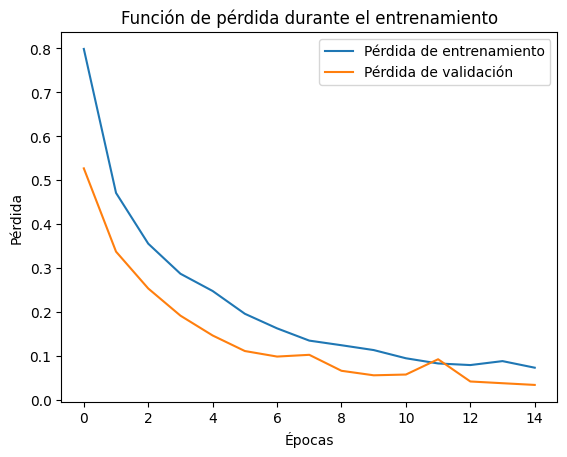

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()

* Podemos observar que disminuye la función del error tanto como las épocas. Esto ayuda a detectar si el modelo está aprediendo correctamente o no.

# **Evaluación**

In [ ]:
loss, accuracy = modelo.evaluate(X_test, y_test)
print(f'Loss: {loss}, Accuracy: {accuracy}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 1.0000 - loss: 0.0348
Loss: 0.03477072715759277, Accuracy: 1.0


* En esta parte se evalúa el rendimiento del modelo con ayuda de la función "*evaluate*". Donde podemos obtener la pérdida y la presición del modelo.

# **Matriz de confusión**

In [ ]:
import numpy as np

In [ ]:
predictions = modelo.predict(X_test)
# Obtener el índice de la clase predicha para cada punto de datos
predicted_classes = np.argmax(predictions, axis=1)
# Obtenemos el índice de la clase real de y_test
actual_classes = np.argmax(y_test, axis=1)

comparison = pd.DataFrame({'Actual Class Index': actual_classes, 'Predicted Class Index': predicted_classes})
# Agregar columnas con los nombres reales y predichos de las flores utilizando iris.target_names
comparison['Actual Flower'] = [iris.target_names[i] for i in actual_classes]
comparison['Predicted Flower'] = [iris.target_names[i] for i in predicted_classes]
# Reordenar las columnas para una mejor visualización
comparison = comparison[['Actual Class Index', 'Actual Flower', 'Predicted Class Index', 'Predicted Flower']]
print(comparison.head())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
   Actual Class Index Actual Flower  Predicted Class Index Predicted Flower
0                   1    versicolor                      1       versicolor
1                   0        setosa                      0           setosa
2                   2     virginica                      2        virginica
3                   1    versicolor                      1       versicolor
4                   1    versicolor                      1       versicolor


* Podemos observar los detalles y acietos del modelo. Hacemos predicciones y comparaciones con los valores.

# **Calcular la matriz de confución y la sensibilidad**

In [21]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, recall_score

y_pred = modelo.predict(X_test)
# Convertir las predicciones a clases
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# Calcular la matriz de confusión
cm = confusion_matrix(y_test_classes, y_pred_classes)
# Calcular la sensibilidad
sensitivity = recall_score(y_test_classes, y_pred_classes, average=None)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


* Usamos la *"confusion_matriz"* y *"recall_scre"* para poder calcular la matriz en cm como queremos la medida y con ayuda de *"sensitivity"* la sensibilidad.

Aqui se calcula la matriz de confusión y la sensibilidad para cada clase, ya que queremos convertir las predicciones a clases. Después la sensibilidad mide la capacidad del modelo para encontrar todas las muestras.

**Visualizar la matriz de confusión y mostrar la sensibilidad para cada clase.**

Sensitivity (Recall) for each class:
Class 0: 1.0
Class 1: 1.0
Class 2: 1.0


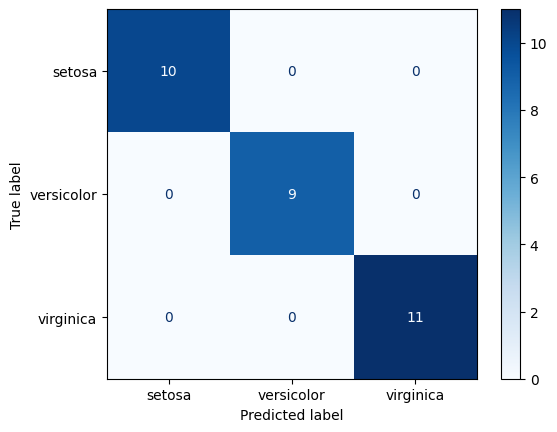

In [22]:
# Visualizar la matriz de confusión como una imagen de colores
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot(cmap='Blues')

# Mostrar la sensibilidad (recall) para cada clase
print('Sensitivity (Recall) for each class:')
for i in range(3):
    print(f'Class {i}: {sensitivity[i]}')


* Podemos observar en la matriz que con colores se ve la sensibilidad y al rededor de los colores fuertes son 0 así que el rendimiento es perfecto.

# Referencias

Evangelista, M. (s.ff). *Clasificación de la flor Iris*. Notas de Redes Neuronales. Gitbook.
Fuente: https://miguelevangelista.gitbook.io/notas-de-redes-neuronales/3.-redes-neuronales-arquitecturas-clasicas/3.4.-tipos-de-redes-neuronales/3.4.2.-red-neuronal-multicapa/ejemplos/clasificacion-de-la-flor-del-iris